In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import functools as ft
import visual_utils as vu
import reliability_utils as ru
import geopandas as gpd
import infrastructure_utils as iu
from shapely import wkt
import seaborn as sns
import random

In [2]:
%%time

# Define Projection 
project_crs = 'epsg:32735'
geo_crs = 'epsg:4326'
# load files

# demographics and HH xtcs
demograhics = pd.read_csv('../data/processed/demographics.csv')
hh_xteristics = pd.read_csv('../data/processed/hh_xteristics.csv')
survey_socio_econ_dists = pd.read_csv('../data/processed/survey_socio_econ_dists.csv')
HH_reliability = pd.read_csv('../data/processed/HH_reliability_closest_line_11_12_23.csv')
hh_grid_dist = pd.read_csv('../data/processed/IV_grid_dist_metrics.csv')


# appliances
appliance_count = pd.read_csv('../data/processed/appliance_count.csv')
appliance_presence = pd.read_csv('../data/processed/appliance_presence_HH.csv')
non_electric_count = pd.read_csv('../data/processed/non_electric_count.csv')

# finances
expenditure = pd.read_csv('../data/processed/expenditure.csv')
loans = pd.read_csv('../data/processed/loan.csv')
poverty = pd.read_csv('../data/processed/poverty.csv')
rent = pd.read_csv('../data/processed/rent.csv')
savings = pd.read_csv('../data/processed/savings.csv')
electricity = pd.read_csv('../data/processed/electricity.csv')

# eicv and combined datasets
# combined_data = pd.read_csv('../data/processed/sample_qsel_14_03_23_0736.csv',low_memory=False)
combined_data = pd.read_csv('../data/processed/sample_qsel.csv',low_memory=False)
eicv_reg_data = pd.read_csv('../data/processed/matched_eicv_reg_25_03_23_2008.csv')

# electricity share
combined_data['elec_share_qsel'] = (combined_data.month_elec_amounts_reg/combined_data.monthly_expenses_qsel)*100 # nisr computation
combined_data['elec_share_nisr'] = (combined_data.m_electricity_payment/combined_data.monthly_expenses_nisr)*100 # nisr computation

# purchase categories
combined_data['purchase_categories'] =(combined_data.m_electricity_payment).apply(vu.purchase_categories)

# Map data
eicv_file = '/home/qsel/Desktop/data/REG_electricity_expenditure/EICV5_Person_Household_Shared_13_02_2023v.csv'
eicv_file = '../data/eicv5/EICV5_Person_Household_Shared_13_02_2023v.csv'
eicv_HH = pd.read_csv(eicv_file, encoding='latin-1', low_memory=False)
survey = iu.get_survey_geopandas_df(eicv_HH, geo_crs, project_crs, project=False)
file = '/home/qsel/Desktop/data/REG_electricity_expenditure/nisr_administrative boundaries/RWA_adm5.shp' # qsel
file = '../data/raw/nisr_administrative boundaries/RWA_adm5.shp' # local
admns = gpd.read_file(file)
admns = admns.rename(columns={
    "NAME_2":"district",
    "NAME_3":"sector",
    "NAME_4":"cell",
    "NAME_5":"village",
})
# Convert to lowercase
columns = ['district','sector','cell','village']
for col in columns:
    admns[col] = admns[col].str.lower() # convert to lower
    admns[col] = admns[col].str.strip() # remove leading and trailing whitespace
admns['unique_villages']=admns['district']+'_'+admns['sector']+'_'+admns['cell']+'_'+admns['village']
dir_path = '/home/qsel/Desktop/data/consumption_data/'
dir_path = '../data/raw/'
districts = gpd.read_file(dir_path+'District_Boundaries.geojson')
districts['district'] = districts['district'].str.lower() # convert to lower Villages_boundaries
# villages = gpd.read_file(dir_path+'Villages_boundaries.geojson')
# villages['village'] = villages['village'].str.lower() # convert to lower 
# sectors = gpd.read_file(dir_path+'Sector_Boundaries.geojson')
# sectors['sector'] = sectors['sector'].str.lower() # convert to lower 



# major towns
dir_path = '/home/qsel/Desktop/data/consumption_data/'
major_towns = pd.read_csv(dir_path+'rwanda_major_towns.csv')
major_towns['geometry'] = major_towns['geometry'].apply(wkt.loads)
major_towns = gpd.GeoDataFrame(major_towns, crs='epsg:4326')

# plots
ur = combined_data.groupby(['district_str','urban_rural'])['hhid'].count().reset_index().pivot(index='district_str',columns='urban_rural',values='hhid').reset_index().rename(columns={'district_str':'district'})
ur['total_district_interviews']=ur[['rural','urban']].sum(axis=1)
ur[['rural','urban']] = round(ur[['rural','urban']].div(ur['total_district_interviews'],axis=0)*100,1)
districts = districts.merge(ur[['district','rural']])


hhs_in_district = combined_data.groupby(['district_str'])['hhid'].count().reset_index().rename(columns={
    'hhid':'total_HHs_in_district',
    'district_str':'district'
})
hhid_w_electricity = combined_data[combined_data.no_electricity==0]
hhid_w_electricity = hhid_w_electricity.groupby('district_str')['hhid'].count().reset_index().rename(columns={'hhid':'count_hhs_electricity','district_str':'district'})
hhid_w_electricity= hhid_w_electricity.merge(hhs_in_district)

hhid_w_electricity['count_hhs_electricity_percent'] = round(hhid_w_electricity['count_hhs_electricity'].div(hhs_in_district.total_HHs_in_district,axis=0)*100,1)
districts = districts.merge(hhid_w_electricity[['district','count_hhs_electricity_percent']])


CPU times: user 3.32 s, sys: 458 ms, total: 3.78 s
Wall time: 50.7 s


#### Geographic distribution of HHs

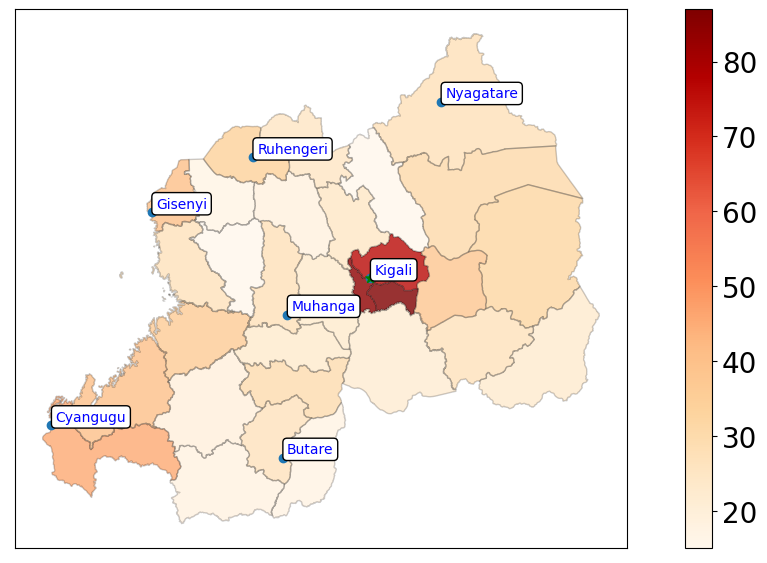

In [3]:
# percentage of HHs with electricity connection
fontsize=28
tckfz = 20
capital=['Kigali']
cities = ['Kigali','Gisenyi','Ruhengeri','Nyagatare','Ruhengeri','Butare','Muhanga','Cyangugu']
cities_gps = major_towns[major_towns.NomAncien.isin(cities)]
capital_gps = major_towns[major_towns.NomAncien.isin(capital)]
fig, ax = plt.subplots(1, figsize = (15, 7))

districts.plot(ax=ax,column='count_hhs_electricity_percent', legend=True, cmap='OrRd') # count_hhs_electricity_percent rural
districts.plot(ax=ax,alpha=0.2,edgecolor='black',color='white') 
cities_gps.plot(ax=ax)
capital_gps.plot(ax=ax,color='green',markersize=50,marker='*')
ax.set_yticklabels([])
ax.set_xticklabels([])
ax.set_xticks([])
ax.set_yticks([])
ax.set_title('')
cb_ax = fig.axes[1] 
cb_ax.tick_params(labelsize=tckfz)
bbox = dict(boxstyle ="round", fc ="1")
for x, y, label in zip(cities_gps.geometry.x, cities_gps.geometry.y, cities_gps.NomAncien):
    ax.annotate(label, xy=(x, y), xytext=(3, 3), textcoords="offset points",
                fontsize=10,color='blue',bbox=bbox)

plt.show()

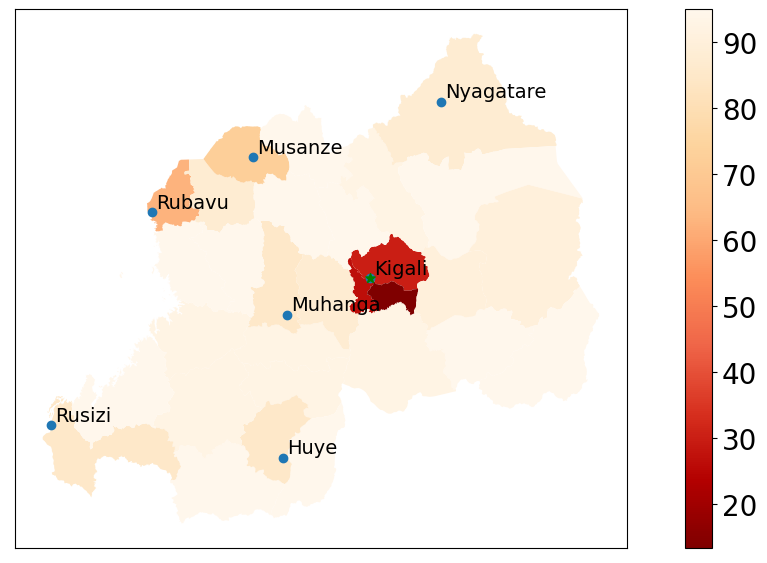

In [6]:
# Percentage of HHs categorized as rural
fontsize=28
tckfz = 20
capital=['Kigali']
cities = ['Kigali','Rubavu','Ruhengeri','Nyagatare','Musanze','Huye','Muhanga','Rusizi']
cities_gps = major_towns[major_towns.Nom2008.isin(cities)]
capital_gps = major_towns[major_towns.Nom2008.isin(capital)]
fig, ax = plt.subplots(1, figsize = (15, 7))

districts.plot(ax=ax,column='rural', legend=True, cmap='OrRd_r')
# districts.plot(ax=ax,alpha=0.2,edgecolor='black')
cities_gps.plot(ax=ax)
capital_gps.plot(ax=ax,color='green',markersize=50,marker='*')
ax.set_yticklabels([])
ax.set_xticklabels([])
ax.set_xticks([])
ax.set_yticks([])
ax.set_title('')
cb_ax = fig.axes[1] 
cb_ax.tick_params(labelsize=tckfz)
for x, y, label in zip(cities_gps.geometry.x, cities_gps.geometry.y, cities_gps.Nom2008):
    ax.annotate(label, xy=(x, y), xytext=(3, 3), textcoords="offset points", fontsize=14)
plt.show()

Check if 100%: 71.80000000000001


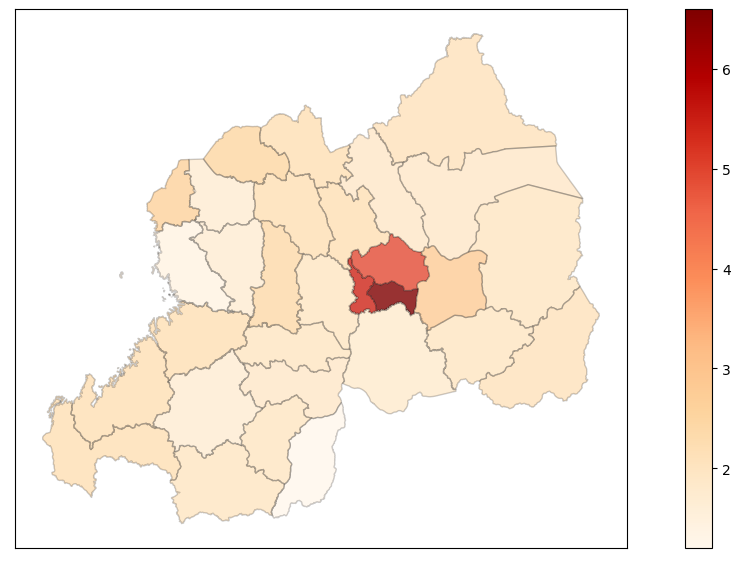

In [246]:

# percentage of appliance ownership

appliance_list = ['Radio','TV','satellite_dish','dvd_player','decoder','music_syst','cooker','laundry_mach','electric_fan','fridge',
                  'generator_as_appliance','hotplate','power_stabilizer','still_camera','video_camera','printer','computer','Mobile_phones','smart_phones']
combined_data['hh_appliance_count'] = combined_data[appliance_list].sum(axis=1)

variable = 'hh_appliance_count'#hh_appliance_count

temp = combined_data
temp = temp.groupby(['district_str'])[variable].mean().reset_index().rename(columns={'district_str':'district'})
# temp[f'{variable}_pct'] = round(temp[variable].div(combined_data[variable].sum(),axis=0)*100,1)
temp[f'{variable}_pct'] = round(temp[variable],1)
districts = districts.merge(temp[['district',f'{variable}_pct']])
summation = temp[f'{variable}_pct'].sum()
print(f'Check if 100%: {summation}')

fontsize=28
tckfz = 20
capital=['Kigali']
cities = ['Kigali','Gisenyi','Ruhengeri','Nyagatare','Ruhengeri','Butare','Muhanga','Cyangugu']
cities_gps = major_towns[major_towns.NomAncien.isin(cities)]
capital_gps = major_towns[major_towns.NomAncien.isin(capital)]
fig, ax = plt.subplots(1, figsize = (15, 7))

districts.plot(ax=ax,column=f'{variable}_pct', legend=True, cmap='OrRd') # count_hhs_electricity_percent rural
districts.plot(ax=ax,alpha=0.2,edgecolor='black',color='white') 
# cities_gps.plot(ax=ax)
# capital_gps.plot(ax=ax,color='green',markersize=50,marker='*')
ax.set_yticklabels([])
ax.set_xticklabels([])
ax.set_xticks([])
ax.set_yticks([])
ax.set_title('')
# cb_ax = fig.axes[1] 
# cb_ax.tick_params(labelsize=tckfz)
# for x, y, label in zip(cities_gps.geometry.x, cities_gps.geometry.y, cities_gps.NomAncien):
#     ax.annotate(label, xy=(x, y), xytext=(3, 3), textcoords="offset points",fontsize=14,color='blue')
plt.show()

## Electricity share in HH expenditure

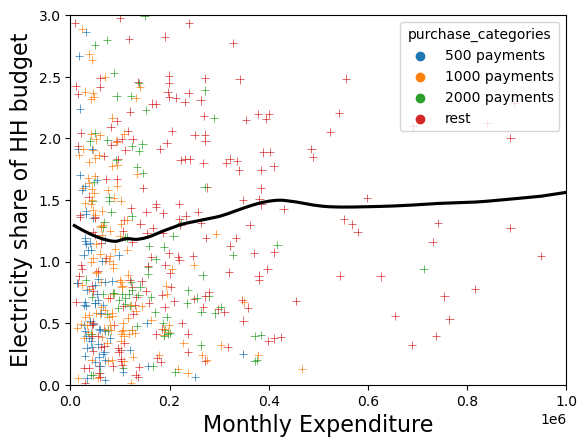

In [10]:
kWh=False
source= 'reg'
if source == 'nisr':
    electricity_var = 'm_electricity_payment' # month_elec_amount_nisr_matched_w_reg
    elec_share = 'elec_share_nisr'
    monthly_expense = 'monthly_expenses_nisr'
    x_label = 'Monthly Expenditure'
    y_label = 'Electricity share of HH budget'
elif source=='reg':
    electricity_var = 'month_elec_amounts_reg' # month_elec_amount_nisr_matched_w_reg
    elec_share = 'elec_share_qsel'
    monthly_expense = 'monthly_expenses_qsel'
    x_label = 'Monthly Expenditure'
    y_label = 'Electricity share of HH budget'

plt_data = combined_data[ (combined_data[electricity_var]!=0)]
hue_order = ['500 payments', '1000 payments', '2000 payments', 'rest']
ax = sns.scatterplot(data=plt_data, x=monthly_expense, y=elec_share, hue="purchase_categories",marker='+',hue_order=hue_order)
ax= sns.regplot(data=plt_data, x=monthly_expense, y=elec_share,scatter=False,lowess=True, color='black',ci=67)

plt.ylim(0,3)
plt.xlim(0,1e+6)
# plt.xscale('log')
plt.xlabel(x_label,fontsize=fontsize)
plt.ylabel(y_label,fontsize=fontsize)
plt.show()

### Reliabilty

In [4]:
dir_path = '~/Desktop/data/REG_Tariffs/LV_lines/'
# dir_path = '../data/raw/LV_lines/'
lines = gpd.read_file(dir_path+'lv_lines.shp')
clean_lines,feeder_bboxs_gdf =  ru.clean_lines(lines)
merged_feeder_reliability = pd.read_csv('../data/processed/merged_feeder_reliability.csv')
feeder_reliability_gdf = feeder_bboxs_gdf.merge(merged_feeder_reliability) # merge feeder bounding boxes and feeder reliability data

# variables
duration_cols = ['outage_duration_2016','outage_duration_2017','outage_duration_2018','outage_duration_2019','outage_duration_2020',]
frequency_cols = ['outage_freq_2016', 'outage_freq_2017','outage_freq_2018','outage_freq_2019','outage_freq_2020']
labels = ['2016','2017','2018','2019','2020']

# household reliability
HH_reliability = pd.read_csv('../data/processed/HH_reliability_closest_line_11_12_23.csv')
hhs_per_feeder = HH_reliability.groupby(['Feeder_Nam'])['hhid'].count().reset_index() # count number of feeders per household
feeder_reliability_gdf =  feeder_reliability_gdf.merge(hhs_per_feeder).rename(columns={'hhid':'num_of_hhs'}) # add number of households per feeder to  feeder reliability dataset
feeder_reliability_gdf['duration_per_outage'] = (feeder_reliability_gdf.mean_outage_duration)/(feeder_reliability_gdf.mean_frequency)
feeder_reliability_gdf['outages_per_day'] = (feeder_reliability_gdf.mean_frequency)/(365)

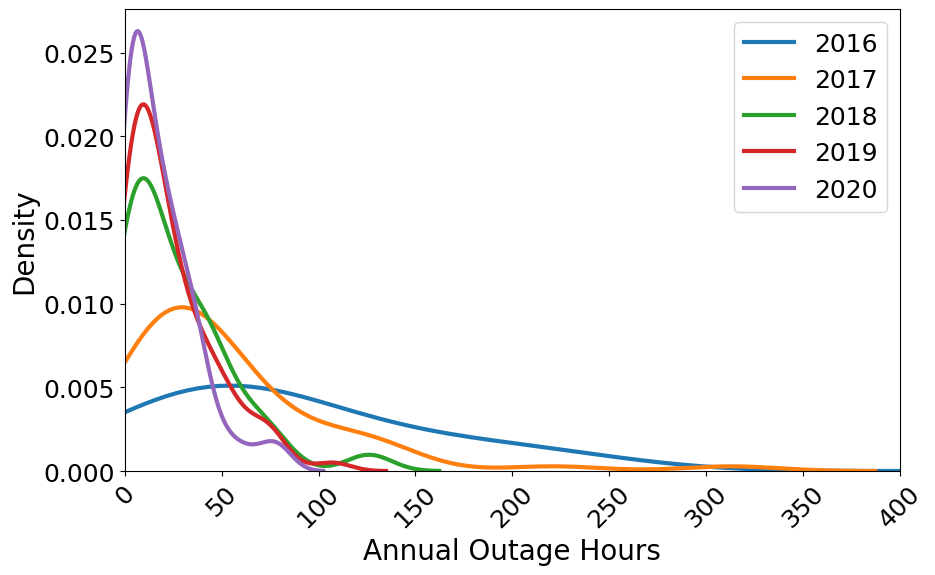

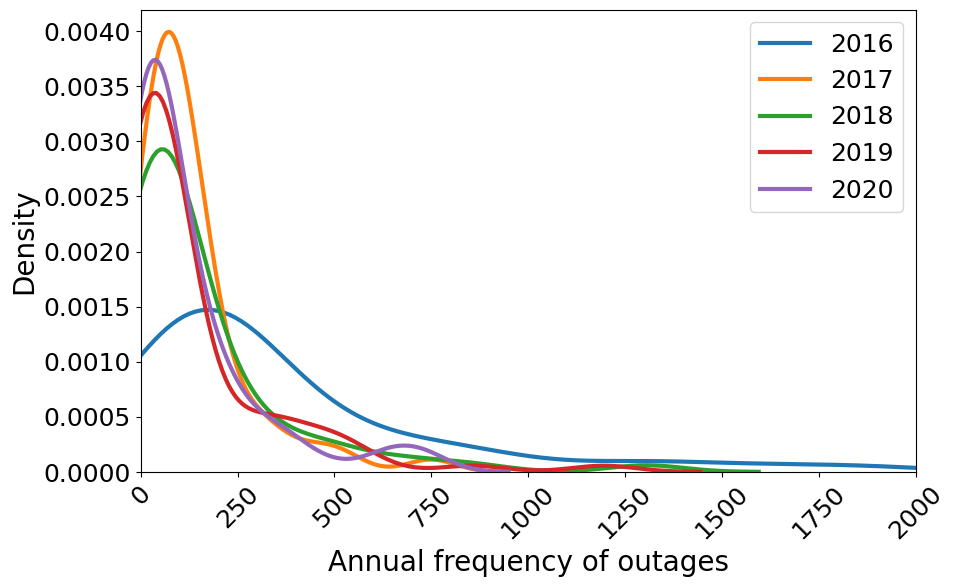

In [15]:

fontsize=20
tckfz = 18
# Create KDE plots for each dataset
fig, ax = plt.subplots(1, figsize=(10, 6))
for i in range(0,len(duration_cols)):
    sns.kdeplot(merged_feeder_reliability[f'{duration_cols[i]}'], label=labels[i], fill=False,ax=ax,lw=3)

plt.xlim(0,400)
plt.ylabel('Density',fontsize=fontsize)
plt.xlabel('Annual Outage Hours', fontsize=fontsize)
plt.xticks(fontsize=tckfz, rotation=45)
plt.yticks(fontsize=tckfz)
plt.legend(fontsize=tckfz)# Display legend
plt.show()

fig, ax = plt.subplots(1, figsize=(10, 6))
for i in range(0,len(frequency_cols)):
    sns.kdeplot(merged_feeder_reliability[f'{frequency_cols[i]}'], label=labels[i], fill=False,ax=ax,lw=3)

plt.xlim(0,2000)
plt.ylabel('Density',fontsize=fontsize)
plt.xlabel('Annual frequency of outages', fontsize=fontsize)
plt.xticks(fontsize=tckfz, rotation=45)
plt.yticks(fontsize=tckfz)
plt.legend(fontsize=tckfz)# Display legend
plt.show()

This is mean_outage_duration


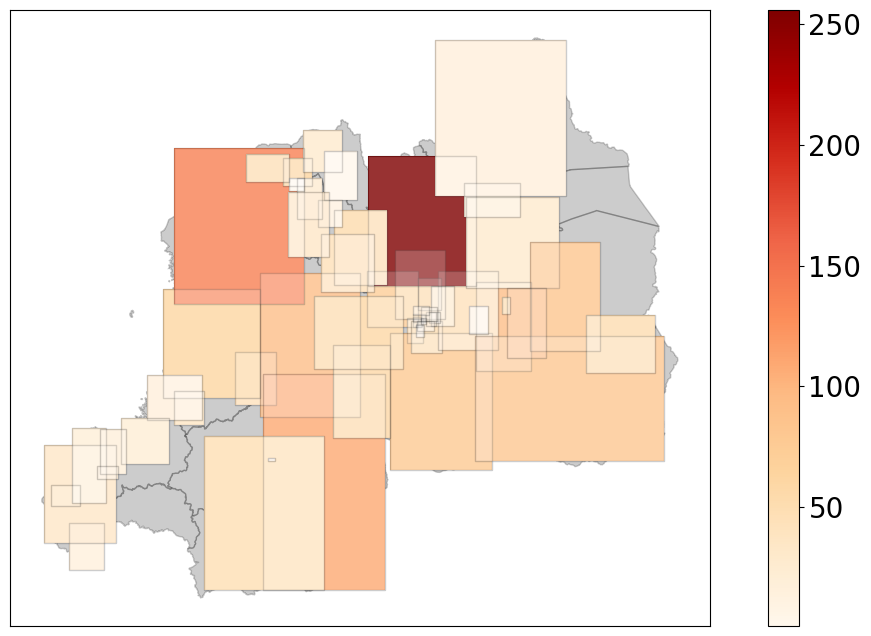

This is duration_per_outage


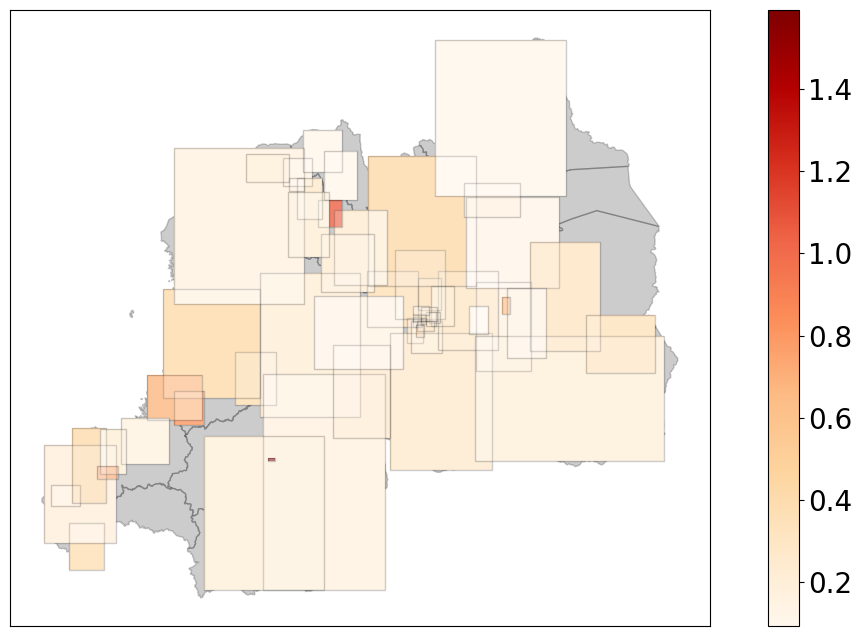

This is outages_per_day


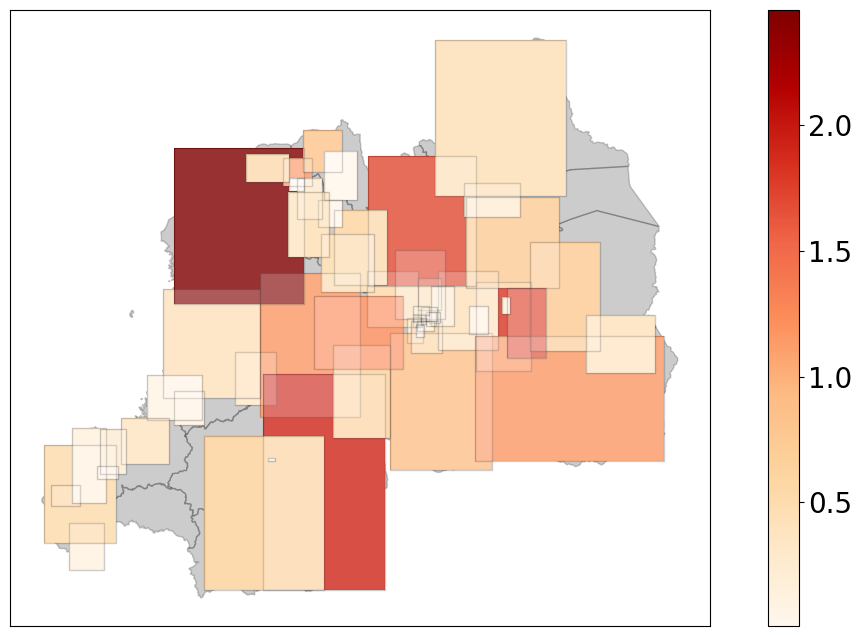

This is num_of_hhs


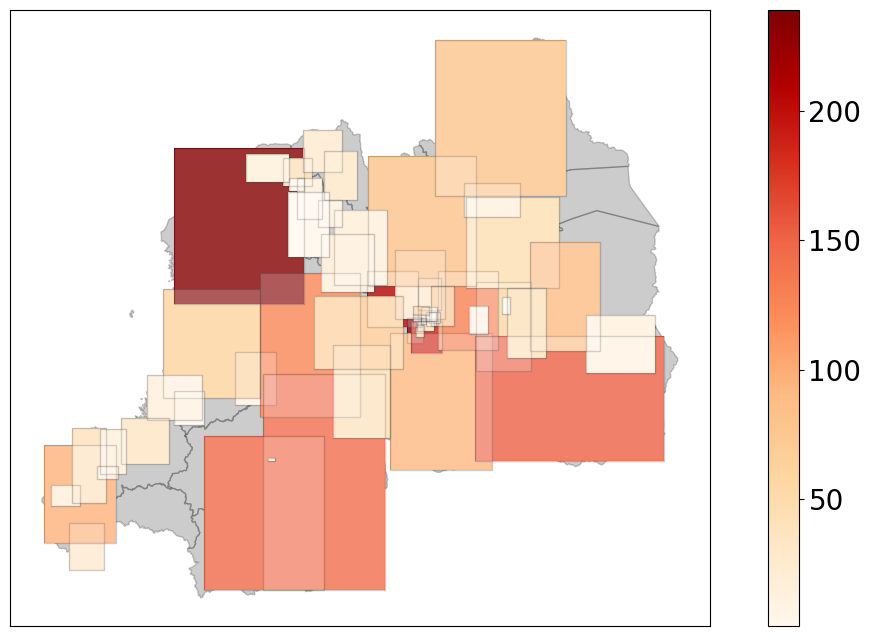

In [23]:
columns = ['mean_outage_duration','duration_per_outage','outages_per_day','num_of_hhs']
tckfz = 20
for col in columns:
    print(f'This is {col}')
    fig, ax = plt.subplots(1, figsize=(15, 8))
    districts.plot(ax=ax,color='black',alpha=0.2,edgecolor='black')
    feeder_reliability_gdf.plot(ax=ax,column=col,legend=True, cmap='OrRd')
    feeder_reliability_gdf.plot(ax=ax,color='white',alpha=0.2,edgecolor='black')
    cb_ax = fig.axes[1] 
    cb_ax.tick_params(labelsize=tckfz)
    plt.tick_params(left = False, right = False , labelleft = False ,
                    labelbottom = False, bottom = False)
    plt.show()

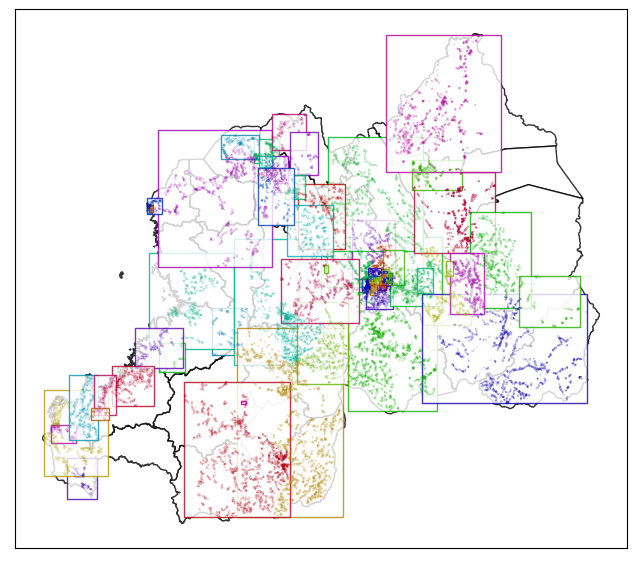

In [9]:


number_of_feeders = len(feeder_bboxs_gdf)
feeder_list = feeder_bboxs_gdf.Feeder_Nam.unique().tolist()
distinct_colors = ru.dark_color_palette(number_of_feeders) # return array of distinct colors
random.shuffle(distinct_colors) # shuffle colors to better visualize feeders on map

fig, ax = plt.subplots(1, figsize = (15, 7))
districts.plot(ax=ax,alpha=0.8,edgecolor='black',color='white')
# feeder_bboxs_gdf.plot(ax=ax,alpha=0.8,edgecolor='black',color='white')

for i in range(0,number_of_feeders):
    feeder_bboxs_gdf[feeder_bboxs_gdf.Feeder_Nam==feeder_list[i]].plot(ax=ax,alpha=0.8,edgecolor=distinct_colors[i],color='white')

for i in range(0,number_of_feeders):
    clean_lines[clean_lines.Feeder_Nam==feeder_list[i]].plot(ax=ax,alpha=0.2,color=distinct_colors[i])
ax.set_yticklabels([])
ax.set_xticklabels([])
ax.set_xticks([])
ax.set_yticks([])
ax.set_title('')
plt.show()

### Infrastructure

In [10]:

dir_path = '/home/qsel/Desktop/data/consumption_data/'
# cell towers
cell_towers = pd.read_csv(dir_path+'rwanda_cell_locations.csv').iloc[:,[0,6,7]]
cell_towers.columns = ["tower_type", "longitude", "latitude"]
cell_towers = gpd.GeoDataFrame(
    cell_towers, geometry=gpd.points_from_xy(cell_towers.longitude, cell_towers.latitude), crs=geo_crs)

# National Paved roads
national_paved_road =  gpd.read_file(dir_path+'national_roads_and_landmarks/National_Road_Paved.shp').to_crs(geo_crs)
# National unPaved roads
national_unpaved_road =  gpd.read_file(dir_path+'national_roads_and_landmarks/National_Road_Unpaved.shp').to_crs(geo_crs)
# bus stations
bus_stations =  gpd.read_file(dir_path+'Bus_stations.geojson').iloc[:-3,:]
# major towns
major_towns = pd.read_csv(dir_path+'rwanda_major_towns.csv')
major_towns['geometry'] = major_towns['geometry'].apply(wkt.loads)
major_towns = gpd.GeoDataFrame(major_towns, crs=geo_crs)

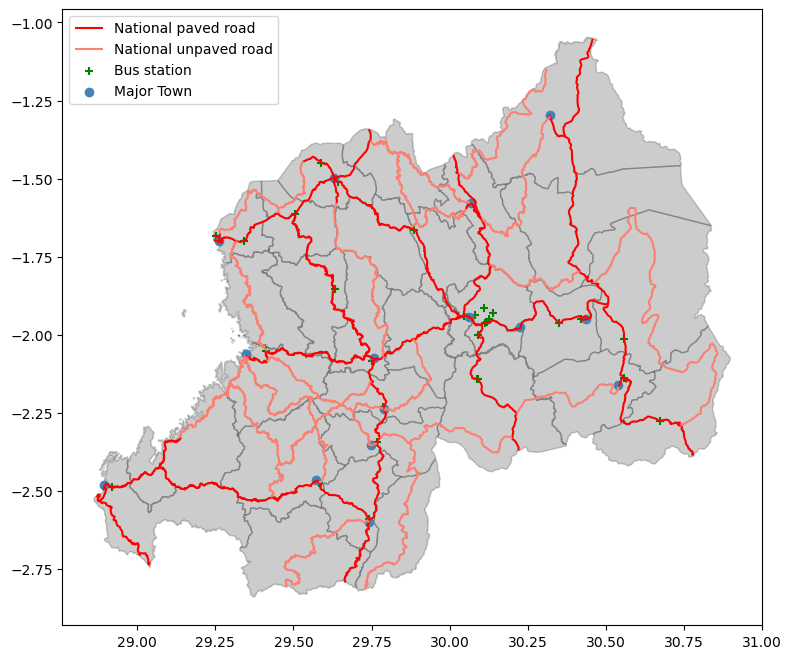

In [11]:
fontsize=28
tckfz = 24
year = 2016
fig, ax = plt.subplots(1, figsize=(15, 8))
districts.plot(ax=ax,color='black',alpha=0.2,edgecolor='black')
# # cell_towers.plot(ax=ax)
# cell_towers.plot(ax=ax,color='purple',label='Cell Tower', markersize=3)
national_paved_road.plot(ax=ax,color='red',label='National paved road')
national_unpaved_road.plot(ax=ax,color='salmon',label='National unpaved road')
bus_stations.plot(ax=ax,color='green',label='Bus station', marker='+')
major_towns.plot(ax=ax,color='steelblue',label='Major Town')


# plt.title(f'SAIDI {year}',fontsize=fontsize)
plt.legend( loc='upper left')
plt.show()

In [12]:
# lines
lines = gpd.read_file('~/Desktop/data/REG_Tariffs/LV_lines/lv_lines.shp')
cleaned_lines =  ru.clean_lines(lines)
cleaned_lines['Feeder_Nam'] = cleaned_lines['Feeder_Nam'].replace(ru.mapping_dict_lines)
cleaned_lines = cleaned_lines.to_crs(geo_crs)

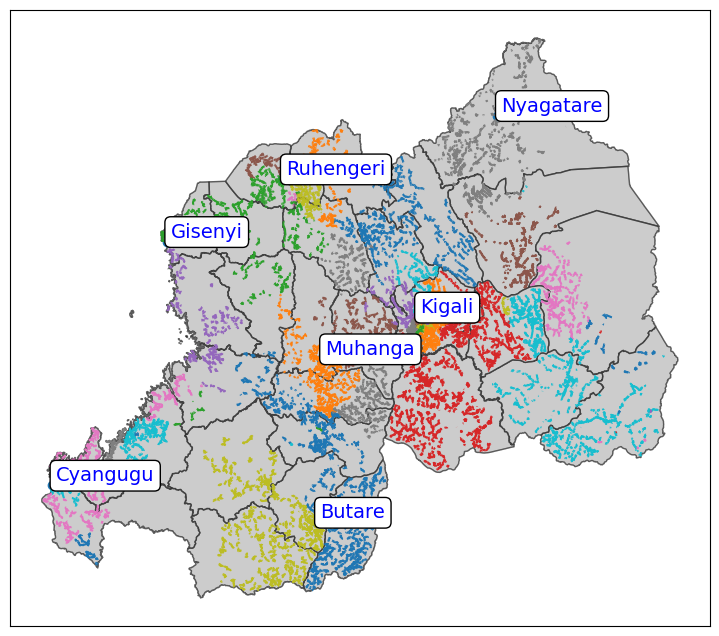

In [26]:
fontsize=28
tckfz = 24
year = 2016
capital=['Kigali']
cities = ['Kigali','Gisenyi','Ruhengeri','Nyagatare','Ruhengeri','Butare','Muhanga','Cyangugu']
cities_gps = major_towns[major_towns.NomAncien.isin(cities)]
capital_gps = major_towns[major_towns.NomAncien.isin(capital)]
fig, ax = plt.subplots(1, figsize=(15, 8))
districts.plot(ax=ax,edgecolor='gray',color='white')
districts.plot(ax=ax,color='black',alpha=0.2,edgecolor='black')

cleaned_lines.plot(ax=ax,column='Feeder_Nam')

cities_gps.plot(ax=ax)
capital_gps.plot(ax=ax,color='green',markersize=50,marker='*')
ax.set_yticklabels([])
ax.set_xticklabels([])
ax.set_xticks([])
ax.set_yticks([])
ax.set_title('')
bbox = dict(boxstyle ="round", fc ="1")
cb_ax = fig.axes[0] 
cb_ax.tick_params(labelsize=tckfz)
for x, y, label in zip(cities_gps.geometry.x, cities_gps.geometry.y, cities_gps.NomAncien):
    ax.annotate(label, xy=(x, y), xytext=(3, 3), textcoords="offset points",fontsize=14,
                color='blue', bbox = bbox)


# plt.title(f'SAIDI {year}',fontsize=fontsize)
# plt.legend( loc='upper left')
plt.tick_params(left = False, right = False , labelleft = False ,
                labelbottom = False, bottom = False)
plt.show()